## 1. The task

Every graph in FRANKENSTEIN is one molecule (Orsini, Frasconi and De Raedt, 2015). A node is an atom and an edge is a chemical bond. The molecules come from the BURSI mutagenicity data, and we predict one label $y\in\{0,1\}$ for the whole molecule: $y=1$ is **mutagenic** (2,401 molecules) and $y=0$ is **non-mutagenic** (1,936).

The dataset is called FRANKENSTEIN because it is stitched together from two others: the chemical symbol of every atom is replaced by an **MNIST image**, 780 pixel intensities. The model cannot read the atom type; it has to recognise it from a picture, while it also learns the chemistry.

The model is the **enhanced classic GNN** of Lecture 17 and Luo, Shi and Wu (ICML 2025), *Can Classic GNNs Be Strong Baselines for Graph-level Tasks?*: a GIN layer wrapped in normalization, dropout, residual connections, a feed-forward network and positional encodings. We call it **GIN⁺**. The readout, the step that turns the node embeddings into one graph vector, is tuned like any other hyperparameter: flat sum, mean and max, a **degree-aware** readout that pools chain ends, chain atoms and branching atoms separately, and the hierarchical poolers **SAGPool**, **DiffPool** and **MinCutPool**.

The notebook follows the UPFD and PROTEINS notebooks of the same model step by step, so the three datasets can be compared trick by trick. It first tunes GIN⁺ on the validation split (Milestone 2) and then runs the same analyses: ablations, readouts, depth, dropout, t-SNE, efficiency, robustness, errors by graph shape and explainability.

Kaggle already has PyTorch, so we only install PyTorch Geometric.

In [1]:
!pip install -q torch_geometric

## 2. Set the experiment budget

All the settings that control run time are here.

A training run lasts at most `epochs` epochs and stops early once validation accuracy has not improved for `patience` epochs. The search tries `n_trials` random configurations, each with every seed in `search_seeds`. The winner is retrained on ten fresh seeds, `final_seeds`; the ablations use the first five, `abl_seeds`, and the depth and dropout sweeps the first three, `sweep_seeds`.

In [2]:
import time
t0 = time.time()
epochs, patience, batch_size = 200, 30, 64
n_trials, search_seeds = 30, [0, 1, 2]
final_seeds = list(range(100, 110))
abl_seeds, sweep_seeds = final_seeds[:5], final_seeds[:3]

## 3. Load FRANKENSTEIN

FRANKENSTEIN is one of the TU Dortmund benchmark datasets, and PyG downloads it with `TUDataset`. Its node features are continuous attributes, which `TUDataset` drops unless we pass `use_node_attr=True`; without it every atom would have an empty feature vector.

The data goes to `/tmp` so that Kaggle does not copy the raw files into the output. PyG warns on every max-pooling call that an optional package would make it faster; we silence that message.

In [3]:
import torch
import warnings
from torch_geometric.datasets import TUDataset
warnings.filterwarnings('ignore', message='.*can be accelerated via')

dataset = TUDataset('/tmp/tud', 'FRANKENSTEIN', use_node_attr=True)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print("graphs =", len(dataset), "   node features =", dataset.num_features, "   device =", device)
print(dataset[0])

graphs = 4337    node features = 780    device = cuda
Data(edge_index=[2, 56], x=[25, 780], y=[1])


## 4. What a FRANKENSTEIN molecule looks like

Before modelling we check the facts the notebook relies on: the edges are stored in both directions, the molecule sizes, how many bonds an atom has, and the range of the pixels. Molecules contain **rings**; the number of independent rings is $|E|-|V|+(\text{connected components})$. Some molecules also have isolated atoms, such as a counter-ion of a salt.

An MNIST image has $28\times28=784$ pixels and we have 780. The file format cut off the last four pixels, which are always black, so we add four zeros to draw the atoms of the first molecule as images.

In [4]:
import networkx as nx
import matplotlib.pyplot as plt
from torch_geometric.utils import to_networkx, degree

def n_rings(g):
    G = to_networkx(g, to_undirected=True)
    return G.number_of_edges() - G.number_of_nodes() + nx.number_connected_components(G)

def image(x):
    return torch.cat([x, x.new_zeros(4)]).view(28, 28)

X = torch.cat([g.x for g in dataset])
sizes = torch.tensor([g.num_nodes for g in dataset]).float()
bonds = torch.cat([degree(g.edge_index[0], g.num_nodes) for g in dataset]).long()
print("undirected graphs:", sum(g.is_undirected() for g in dataset), "of", len(dataset))
print("nodes per graph: mean =", round(sizes.mean().item(), 1), "  median =", sizes.median().item(), "  max =", int(sizes.max()))
print("edges per graph: mean =", round(sum(g.num_edges for g in dataset) / 2 / len(dataset), 1))
print("molecules with an isolated atom:", sum(g.has_isolated_nodes() for g in dataset))
print("atoms with 0, 1, 2, ... bonds:", torch.bincount(bonds).tolist())
print("molecules without a ring:", sum(n_rings(g) == 0 for g in dataset))
print("pixels: min =", X.min().item(), "  max =", X.max().item(), "  share that is zero =", round((X == 0).float().mean().item(), 3))
print("different images:", len(torch.unique(X, dim=0)), "for", len(X), "atoms")
fig, ax = plt.subplots(1, 10, figsize=(14, 1.6))
for a, x in zip(ax, dataset[0].x): a.imshow(image(x), cmap='gray_r')
for a in ax: a.axis('off')
plt.show()

undirected graphs: 4337 of 4337
nodes per graph: mean = 16.9   median = 16.0   max = 214
edges per graph: mean = 17.9
molecules with an isolated atom: 209
atoms with 0, 1, 2, ... bonds: [298, 16052, 32941, 22834, 1158]
molecules without a ring: 753
pixels: min = 0.0   max = 1.0   share that is zero = 0.858
different images: 23562 for 73283 atoms


## 5. Split and add positional encodings

FRANKENSTEIN has no official split. We use a stratified 80/10/10 split with `random_state=0`, the same rule as on PROTEINS, so every model is scored on exactly the same 434 test molecules. One molecule moves accuracy by $0.23\%$.

The pixels already lie in $[0,1]$, so we do not rescale them; many border pixels are constant and could not be standardised anyway.

The sixth trick of Luo et al. is a **positional encoding** $\mathbf{p}_v$, a vector that tells each node where it sits in the graph. We use random-walk encodings,

$\mathbf{p}_v=\big[(\mathbf{D}^{-1}\mathbf{A})^{k}\big]_{vv},\quad k=1,\dots,16,$

the probability that a random walk from $v$ is back at $v$ after $k$ steps. An odd return is only possible through an odd ring, so these numbers tell the model about rings with 5 atoms.

In [5]:
import numpy as np
from sklearn.model_selection import train_test_split
from torch_geometric.transforms import AddRandomWalkPE

y_all = np.array([g.y.item() for g in dataset])
train_idx, rest = train_test_split(np.arange(len(y_all)), train_size=0.8, stratify=y_all, random_state=0)
val_idx, test_idx = train_test_split(rest, train_size=0.5, stratify=y_all[rest], random_state=0)

rw = AddRandomWalkPE(walk_length=16, attr_name='pe')
train_set, val_set, test_set = [[rw(dataset[int(i)].clone()) for i in idx] for idx in [train_idx, val_idx, test_idx]]
g = train_set[0]
print(g)
print("encoding of node 0:", g.pe[0].numpy().round(3))

Data(edge_index=[2, 40], x=[19, 780], y=[1], pe=[19, 16])
encoding of node 0: [0.    0.479 0.    0.32  0.007 0.252 0.017 0.215 0.028 0.192 0.038 0.175
 0.047 0.162 0.054 0.152]


## 6. Class balance and reference points

Every number later in the notebook needs something to be compared with. We use three references on the test split:

- always predicting the larger class;
- a logistic regression on $\log|V|$, the size of the molecule alone;
- a logistic regression on a **bag of nodes**: $\log|V|$ and the average image of the molecule's atoms. It sees the composition of the molecule but none of its bonds. With 781 inputs it overfits easily, so its regularisation is chosen on the validation split.

If a GNN cannot beat the third one, the graph structure adds nothing to the composition.

In [6]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

y_train, y_val, y_test = y_all[train_idx], y_all[val_idx], y_all[test_idx]
for s, yy in zip(['train', 'val', 'test'], [y_train, y_val, y_test]):
    print(s, "  graphs =", len(yy), "  non-mutagenic (0) =", (yy == 0).sum(), "  mutagenic (1) =", (yy == 1).sum())
logn = lambda d: np.log([[g.num_nodes] for g in d])
bag = lambda d: np.array([[np.log(g.num_nodes)] + g.x.mean(0).tolist() for g in d])
size_acc = LogisticRegression().fit(logn(train_set), y_train).score(logn(test_set), y_test)
lrs = [make_pipeline(StandardScaler(), LogisticRegression(C=c, max_iter=2000)).fit(bag(train_set), y_train) for c in [1e-4, 1e-3, 1e-2, 1e-1, 1]]
bag_acc = max(lrs, key=lambda m: m.score(bag(val_set), y_val)).score(bag(test_set), y_test)
majority = max(np.mean(y_test == 0), np.mean(y_test == 1))
print("\ntest accuracy, always the larger class:", round(majority, 4))
print("test accuracy from log|V| alone:      ", round(size_acc, 4))
print("test accuracy from the bag of nodes:   ", round(bag_acc, 4))

train   graphs = 3469   non-mutagenic (0) = 1549   mutagenic (1) = 1920
val   graphs = 434   non-mutagenic (0) = 193   mutagenic (1) = 241
test   graphs = 434   non-mutagenic (0) = 194   mutagenic (1) = 240

test accuracy, always the larger class: 0.553
test accuracy from log|V| alone:       0.576
test accuracy from the bag of nodes:    0.5484


## 7. The message-passing layer: GIN

The core of every block is a GIN layer (Xu et al., ICLR 2019):

$\mathbf{h}_v'=\mathrm{MLP}\Big((1+\epsilon)\,\mathbf{h}_v+\sum_{u\in\mathcal{N}(v)}\mathbf{h}_u\Big).$

GCN averages the neighbours; GIN adds them up and passes the sum through a two-layer MLP. A sum keeps track of *how many* neighbours a node has, so GIN can tell an atom with one neighbour of a kind from an atom with three, which a mean cannot. This makes GIN as powerful as the 1-Weisfeiler–Leman test. We learn $\epsilon$ (`train_eps=True`). Inside a block the layer keeps the width `hidden` of its input.

In [7]:
import torch.nn.functional as F
from torch.nn import Linear, BatchNorm1d, Identity, Sequential, ReLU, Dropout, ModuleList
from torch_geometric.utils import to_dense_batch, to_dense_adj
from torch_geometric.nn import GINConv
make_conv = lambda h: GINConv(Sequential(Linear(h, h), BatchNorm1d(h), ReLU(), Linear(h, h)), train_eps=True)
conv = make_conv(16)
print("one GIN layer:", (g.num_nodes, 16), "->", tuple(conv(torch.randn(g.num_nodes, 16), g.edge_index).shape))

one GIN layer: (19, 16) -> (19, 16)


## 8. One GIN⁺ block

Luo et al. wrap every message-passing layer in the same block (Lecture 17, *The Enhanced Classic GNN*):

1. **Message passing** with the GIN layer above.
2. **Normalization**: batch norm keeps every feature on the same scale from batch to batch.
3. **Activation and dropout**: ReLU, then each value is zeroed with probability $p$ and the rest scaled by $1/(1-p)$.
4. **Residual connection**: $\mathbf{h}_v^{l}=\mathrm{Dropout}(\sigma(\mathrm{BN}(\cdots)))+\mathbf{h}_v^{l-1}$.
5. **Feed-forward network**: $\mathrm{FFN}(\mathbf{h})=\mathrm{BN}\big(\sigma(\mathbf{h}\mathbf{W}_1)\mathbf{W}_2+\mathbf{h}\big)$, applied to every node.

Each trick has a switch (`norm`, `res`, `ffn`, and `dropout=0`) so that we can remove it later. The first trick of the paper, **edge features**, cannot be used: PyG's FRANKENSTEIN stores nothing on its bonds.

In [8]:
BLOCK_EXTRA = []

class Block(torch.nn.Module):
    def __init__(self, h, dropout, norm, res, ffn):
        super().__init__()
        self.conv = make_conv(h)
        self.bn = BatchNorm1d(h) if norm else Identity()
        self.ffn = Sequential(Linear(h, 2 * h), ReLU(), Dropout(dropout), Linear(2 * h, h)) if ffn else None
        self.bn2 = BatchNorm1d(h) if (ffn and norm) else Identity()
        self.dropout, self.res = dropout, res

    def forward(self, x, edge_index, batch=None):
        h = F.dropout(self.bn(self.conv(x, edge_index)).relu(), self.dropout, self.training)
        if self.res:
            h = h + x
        if self.ffn is not None:
            h = self.bn2(h + self.ffn(h))
        return h

blk = Block(16, 0.2, True, True, True)
print("one block:", (g.num_nodes, 16), "->", tuple(blk(torch.randn(g.num_nodes, 16), g.edge_index).shape))

one block: (19, 16) -> (19, 16)


## 9. From node embeddings to one graph vector

The readout must turn a molecule of any size into one vector of fixed size, and must not depend on the order in which the atoms are stored. We compare seven readouts:

- **sum**, **mean** and **max**: flat, one-shot pooling over all nodes.
- **degree-aware**: $\mathbf{h}_G=[\,\mathrm{mean}(\deg\le1)\,\|\,\mathrm{mean}(\deg=2)\,\|\,\mathrm{mean}(\deg\ge3)\,]$. The atoms have no type label, so we group them by their place in the skeleton: chain ends, chain or ring atoms, and branching atoms. Each group gets its own slot and an empty group contributes zeros. This is the FRANKENSTEIN counterpart of the news-aware readout on UPFD and the type-aware readout on PROTEINS.
- **SAGPool** (Lee et al., ICML 2019): a graph convolution gives every node a score $z_v=\tanh(\mathrm{GCN}(\mathbf{H}))_v$; the top half of the nodes is kept, their embeddings are multiplied by their scores, and the kept nodes are read out with mean $\|$ max. It learns *which* nodes matter. We rank the nodes by the raw score before the $\tanh$ (the order is the same, since $\tanh$ is increasing) because PyG's `SAGPooling` ranks after it: once $\tanh$ saturates, many nodes tie at exactly $1.0$, the tie is broken by node index, and the readout stops being permutation invariant.
- **DiffPool** (Ying et al., NeurIPS 2018): a soft assignment $\mathbf{S}=\mathrm{softmax}(\mathbf{H}\mathbf{W}_S)\in\mathbb{R}^{n\times k}$ maps the nodes onto $k$ clusters, giving $\mathbf{H}'=\mathbf{S}^\top\mathbf{H}$ and $\mathbf{A}'=\mathbf{S}^\top\mathbf{A}\mathbf{S}$. A link loss and an entropy loss are added to training.
- **MinCutPool** (Bianchi et al., ICML 2020): the same soft assignment, trained with a normalized-cut loss and an orthogonality loss that push the clusters to be balanced and well separated.

A molecule has **functional groups** and rings, small sets of atoms that act together, so DiffPool and MinCutPool have something to find. We use $k=5$ clusters, a bit more than a quarter of the average molecule, run one dense graph convolution on the pooled graph and average the clusters. Both need the graphs as padded dense tensors; a mini-batch is padded only to its largest molecule. MinCutPool divides by the degrees of the clusters, which would be zero for a molecule without bonds (our *no edges* ablation), so we add self-loops before it.

Each node enters with $\mathbf{h}_v^{(0)}=[\mathbf{W}_x\mathbf{x}_v\,\|\,\mathbf{W}_p\mathrm{BN}(\mathbf{p}_v)]$: the 16 encoding values are normalised and mapped to 16 of the `hidden` dimensions, or to none if `pe=False`.

In [9]:
from torch_geometric.nn import MLP, GCNConv, DenseGCNConv, DenseGraphConv, dense_diff_pool, dense_mincut_pool
from torch_geometric.nn.pool.select.topk import topk
from torch_geometric.nn import global_mean_pool, global_max_pool, global_add_pool
from torch_geometric.utils import to_dense_batch, to_dense_adj

flat = dict(mean=global_mean_pool, max=global_max_pool, add=global_add_pool)
F_IN, PE_DIM = 780, 16

def role(edge_index, n):
    return (degree(edge_index[0], n).long() - 1).clamp(0, 2)  # 0: at most one bond, 1: two, 2: three or more

class Net(torch.nn.Module):
    def __init__(self, hidden=64, layers=3, dropout=0.2, pool='mean',
                 norm=True, res=True, ffn=True, pe=True, clusters=5, **kw):
        super().__init__()
        self.use_pe, self.pool = pe, pool
        self.node = Linear(F_IN, hidden - 16 if pe else hidden)
        self.pe_norm, self.pe_lin = BatchNorm1d(PE_DIM), Linear(PE_DIM, 16)
        extra = {k: kw[k] for k in BLOCK_EXTRA if k in kw}
        self.blocks = ModuleList([Block(hidden, dropout, norm, res, ffn, **extra) for _ in range(layers)])
        if pool == 'sag':
            self.score = GCNConv(hidden, 1)
        if pool in ['diff', 'mincut']:
            self.assign = Linear(hidden, clusters)
            self.dconv = DenseGCNConv(hidden, hidden) if pool == 'diff' else DenseGraphConv(hidden, hidden)
        out = dict(sag=2 * hidden, degree=3 * hidden).get(pool, hidden)
        self.head = MLP([out, hidden, 2], dropout=dropout, norm=None)
        self.aux = torch.zeros(())

    def nodes(self, x, edge_index, pe, batch):
        h = self.node(x)
        if self.use_pe:
            h = torch.cat([h, self.pe_lin(self.pe_norm(pe))], dim=1)
        for b in self.blocks:
            h = b(h, edge_index, batch)
        return h

    def embed(self, x, edge_index, pe, batch=None):
        if batch is None:
            batch = edge_index.new_zeros(x.size(0))
        h = self.nodes(x, edge_index, pe, batch)
        self.aux = h.new_zeros(())
        if self.pool in flat:
            return flat[self.pool](h, batch)
        if self.pool == 'degree':
            G = int(batch.max()) + 1
            kind = role(edge_index, x.size(0))
            return torch.cat([global_mean_pool(h[kind == t], batch[kind == t], G) for t in range(3)], dim=1)
        if self.pool == 'sag':
            z = self.score(h, edge_index).view(-1)
            keep = topk(z, 0.5, batch)
            hs, bs, G = h[keep] * torch.tanh(z[keep]).view(-1, 1), batch[keep], int(batch.max()) + 1
            return torch.cat([global_mean_pool(hs, bs, G), global_max_pool(hs, bs, G)], dim=1)
        xd, mask = to_dense_batch(h, batch)
        adj = to_dense_adj(edge_index, batch, max_num_nodes=xd.size(1))
        s, _ = to_dense_batch(self.assign(h), batch)
        if self.pool == 'diff':
            xp, ap, l1, l2 = dense_diff_pool(xd, adj, s, mask)
        else:
            xp, ap, l1, l2 = dense_mincut_pool(xd, adj + torch.eye(adj.size(1), device=adj.device), s, mask)
        self.aux = l1 + l2
        return self.dconv(xp, ap).relu().mean(1)

    def forward(self, x, edge_index, pe, batch=None):
        return self.head(self.embed(x, edge_index, pe, batch))

for p in ['mean', 'degree', 'sag', 'diff', 'mincut']:
    out = Net(pool=p)(g.x, g.edge_index, g.pe)
    print(f"{p:7s} readout -> logits {tuple(out.shape)}")

mean    readout -> logits (1, 2)
degree  readout -> logits (1, 2)
sag     readout -> logits (1, 2)
diff    readout -> logits (1, 2)
mincut  readout -> logits (1, 2)


## 10. Train with early stopping on validation accuracy

We minimise cross-entropy, plus the auxiliary losses of DiffPool or MinCutPool when one of them is the readout, with Adam on mini-batches of training graphs. Gradients are clipped to norm 5: without batch norm the sums inside a deep stack can blow up, and a run whose loss becomes NaN stops and keeps its best weights so far. After every epoch we measure validation accuracy, keep the best weights, and stop once it has not improved for `patience` epochs. The test split is never used here.

`predict` returns $P(y=1\mid G)$, the probability of *mutagenic*, for every graph, and `scores` turns those probabilities into accuracy, macro-F1 and ROC-AUC. Accuracy is the primary metric, as in the TU benchmark literature; the classes are 55/45, so we also report macro-F1 and ROC-AUC.

In [10]:
import copy
from torch_geometric import seed_everything
from torch_geometric.loader import DataLoader
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

def batches(gs, size=256):
    return [b.to(device) for b in DataLoader(gs, batch_size=size)]

val_b, test_b = batches(val_set), batches(test_set)

@torch.no_grad()
def predict(model, bs):
    model.eval()
    p = torch.cat([model(b.x, b.edge_index, b.pe, b.batch).softmax(1)[:, 1] for b in bs]).cpu().numpy()
    return np.nan_to_num(p, nan=0.5)

def scores(y, p):
    return dict(acc=accuracy_score(y, p > .5), f1=f1_score(y, p > .5, average='macro'), auc=roc_auc_score(y, p))

def fit(c, seed, tr=None, va=None):
    tr, va = tr or train_set, va or val_b
    yv = torch.cat([b.y for b in va]).cpu().numpy()
    seed_everything(seed)
    model = Net(**c).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=c['lr'], weight_decay=c['wd'])
    loader = DataLoader(tr, batch_size=batch_size, shuffle=True)
    best, wait, state = -1, 0, None
    for epoch in range(epochs):
        model.train()
        for b in loader:
            b = b.to(device)
            opt.zero_grad()
            loss = F.cross_entropy(model(b.x, b.edge_index, b.pe, b.batch), b.y) + model.aux
            if not torch.isfinite(loss):
                break
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()
        if not torch.isfinite(loss):
            break
        acc = accuracy_score(yv, predict(model, va) > .5)
        if acc > best:
            best, wait, state = acc, 0, copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait == patience:
                break
    model.load_state_dict(state)
    return model, best

## 11. Reference: the plain GIN

Before adding anything we train a textbook starting point with every trick switched off (no normalization, residuals, FFN or positional encoding): two GIN layers of width 64, mean readout, and the dropout ($0.5$), learning rate ($0.01$) and weight decay ($5\cdot10^{-4}$) of Kipf and Welling's original GCN. All three FRANKENSTEIN notebooks use the same reference settings, so their plain baselines are comparable. It runs on the ten final seeds.

In [11]:
plain = dict(hidden=64, layers=2, dropout=0.5, pool='mean', norm=False, res=False, ffn=False, pe=False, lr=0.01, wd=5e-4)
base = pd.DataFrame([scores(y_test, predict(fit(plain, s)[0], test_b)) for s in final_seeds])
print(base.agg(['mean', 'std']).round(4))

         acc      f1     auc
mean  0.6525  0.6455  0.7012
std   0.0216  0.0196  0.0185


## 12. The search space

Like Luo et al. we keep all tricks switched on (`norm`, `res`, `ffn`, `pe`) and tune width, depth, dropout, the readout, the learning rate and the weight decay. The readout is searched like any other hyperparameter, so each model on each dataset gets the pooling that suits it. The full grid is too large, so we draw `n_trials` configurations at random (Bergstra and Bengio, 2012).

In [12]:
import random
space = dict(hidden=[32, 64, 128], layers=[1, 2, 3, 4], dropout=[0.0, 0.1, 0.2, 0.5],
             pool=['mean', 'max', 'add', 'degree', 'sag', 'diff', 'mincut'], lr=[1e-3, 3e-3, 1e-2], wd=[0.0, 1e-5, 1e-4])
random.seed(0)
trials = [{k: random.choice(v) for k, v in space.items()} for _ in range(n_trials)]
print(len(trials), "of", np.prod([len(v) for v in space.values()]), "configurations")
print("readouts drawn:", pd.Series([t['pool'] for t in trials]).value_counts().to_dict())

30 of 3024 configurations
readouts drawn: {'mean': 7, 'add': 6, 'max': 5, 'sag': 5, 'mincut': 4, 'degree': 2, 'diff': 1}


## 13. Run the search

Each configuration is trained with every seed in `search_seeds` and scored by its mean validation accuracy. The validation split has 434 molecules, so one molecule moves accuracy by about $0.23\%$; averaging over seeds keeps the ranking from following noise.

In [13]:
rows = []
for i, c in enumerate(trials):
    t = time.time()
    v = [fit(c, s)[1] for s in search_seeds]
    rows.append(dict(c, val=np.mean(v), val_std=np.std(v)))
    print(f"{i:2d}  val = {np.mean(v):.4f} ± {np.std(v):.4f}  ({time.time() - t:.0f}s)  {c}")
search = pd.DataFrame(rows)

 0  val = 0.7404 ± 0.0076  (128s)  {'hidden': 64, 'layers': 4, 'dropout': 0.0, 'pool': 'add', 'lr': 0.01, 'wd': 1e-05}
 1  val = 0.7258 ± 0.0033  (151s)  {'hidden': 64, 'layers': 3, 'dropout': 0.5, 'pool': 'add', 'lr': 0.01, 'wd': 0.0}
 2  val = 0.7404 ± 0.0076  (75s)  {'hidden': 128, 'layers': 2, 'dropout': 0.2, 'pool': 'max', 'lr': 0.001, 'wd': 0.0001}
 3  val = 0.7389 ± 0.0115  (76s)  {'hidden': 64, 'layers': 2, 'dropout': 0.2, 'pool': 'mean', 'lr': 0.01, 'wd': 0.0}
 4  val = 0.7204 ± 0.0071  (154s)  {'hidden': 128, 'layers': 3, 'dropout': 0.5, 'pool': 'sag', 'lr': 0.001, 'wd': 1e-05}
 5  val = 0.7166 ± 0.0019  (151s)  {'hidden': 64, 'layers': 3, 'dropout': 0.1, 'pool': 'sag', 'lr': 0.003, 'wd': 1e-05}
 6  val = 0.7350 ± 0.0147  (152s)  {'hidden': 128, 'layers': 3, 'dropout': 0.0, 'pool': 'mincut', 'lr': 0.01, 'wd': 0.0}
 7  val = 0.7527 ± 0.0057  (153s)  {'hidden': 32, 'layers': 4, 'dropout': 0.0, 'pool': 'sag', 'lr': 0.003, 'wd': 1e-05}
 8  val = 0.7519 ± 0.0107  (105s)  {'hidden'

## 14. The best configuration

We rank by mean validation accuracy and keep the top configuration. Each panel shows every trial's validation accuracy against one hyperparameter: a panel where the values separate marks a choice that matters, a flat one marks a choice that does not.

    hidden  layers  dropout    pool     lr      wd     val  val_std
27     128       3      0.2  degree  0.001  0.0000  0.7558   0.0086
7       32       4      0.0     sag  0.003  0.0000  0.7527   0.0057
8       32       3      0.0     max  0.010  0.0000  0.7519   0.0107
10     128       4      0.0     add  0.010  0.0000  0.7488   0.0151
19      64       3      0.1     max  0.001  0.0001  0.7465   0.0114
29      64       2      0.2     add  0.010  0.0000  0.7450   0.0039
15      32       2      0.0  mincut  0.001  0.0001  0.7435   0.0113
25      64       2      0.0    diff  0.001  0.0001  0.7419   0.0050
22      32       1      0.0    mean  0.001  0.0001  0.7419   0.0038
18     128       3      0.0     add  0.010  0.0000  0.7412   0.0060

best: {'hidden': 128, 'layers': 3, 'dropout': 0.2, 'pool': 'degree', 'lr': 0.001, 'wd': 0.0, 'norm': True, 'res': True, 'ffn': True, 'pe': True}


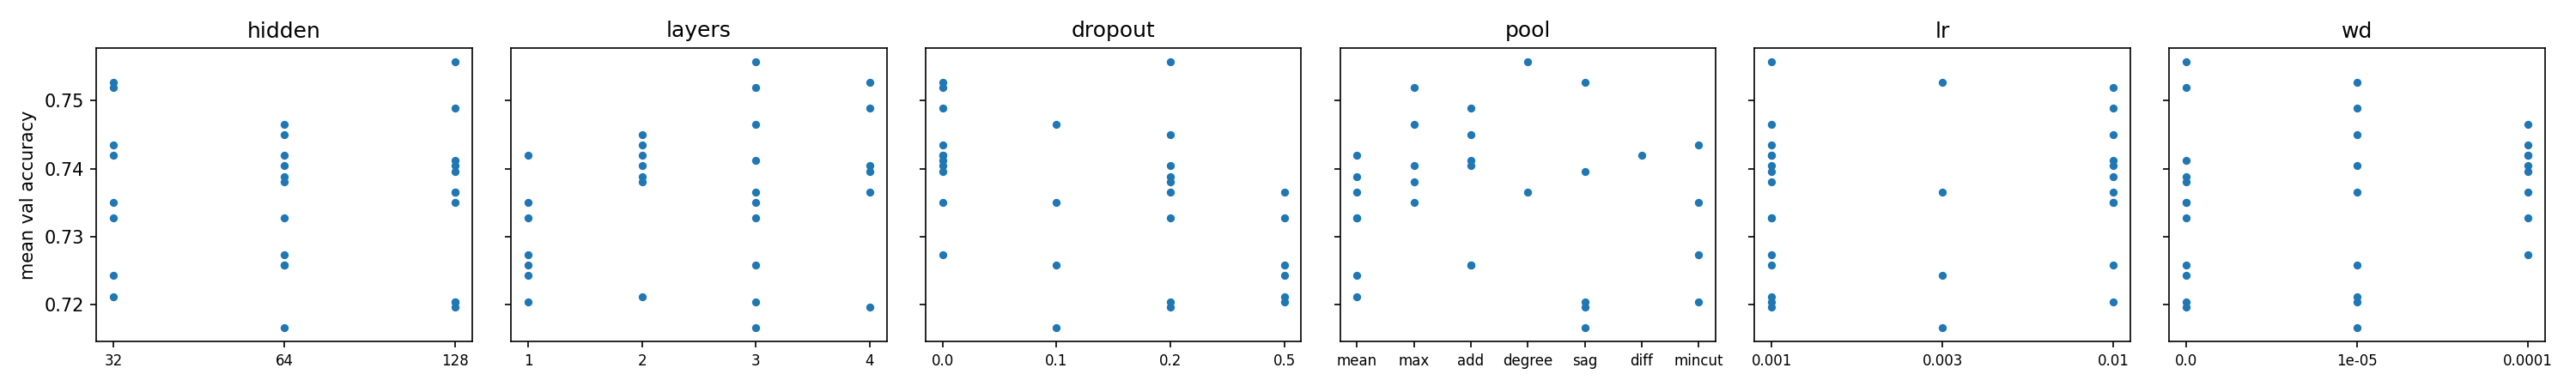

In [14]:
search = search.sort_values('val', ascending=False)
print(search.head(10).round(4).to_string())
best = dict(trials[search.index[0]], norm=True, res=True, ffn=True, pe=True)
print("\nbest:", best)
fig, ax = plt.subplots(1, len(space), figsize=(20, 3), sharey=True)
for a, k in zip(ax, space):
    a.scatter(search[k].map(space[k].index), search.val, s=12)
    a.set_xticks(range(len(space[k])), [str(v) for v in space[k]], fontsize=8)
    a.set_title(k)
ax[0].set_ylabel("mean val accuracy")
plt.tight_layout(); plt.savefig('ginp_search.png', dpi=150); plt.show()

## 15. Test the tuned GIN⁺ on ten fresh seeds

The search used other seeds. We retrain the chosen configuration on the ten final seeds and score each run once on the 434 test molecules.

In [15]:
runs = [fit(best, s) for s in final_seeds]
P = np.stack([predict(m, test_b) for m, _ in runs])
tuned = pd.DataFrame([scores(y_test, p) for p in P])
print(pd.DataFrame({'plain': base.mean(), 'plain std': base.std(), 'tuned': tuned.mean(), 'tuned std': tuned.std()}).round(4))

      plain  plain std   tuned  tuned std
acc  0.6525     0.0216  0.7196     0.0197
f1   0.6455     0.0196  0.7125     0.0216
auc  0.7012     0.0185  0.7924     0.0152


## 16. The model we analyse

Analyses that need a single model use the run with the highest validation accuracy among the ten; picking the highest test accuracy would be peeking at the test set. Its confusion matrix shows whether the errors fall mostly on one class.

seed 101   val acc = 0.7604   test: {'acc': 0.7304, 'f1': 0.7253, 'auc': 0.8009}
trainable parameters: 436453


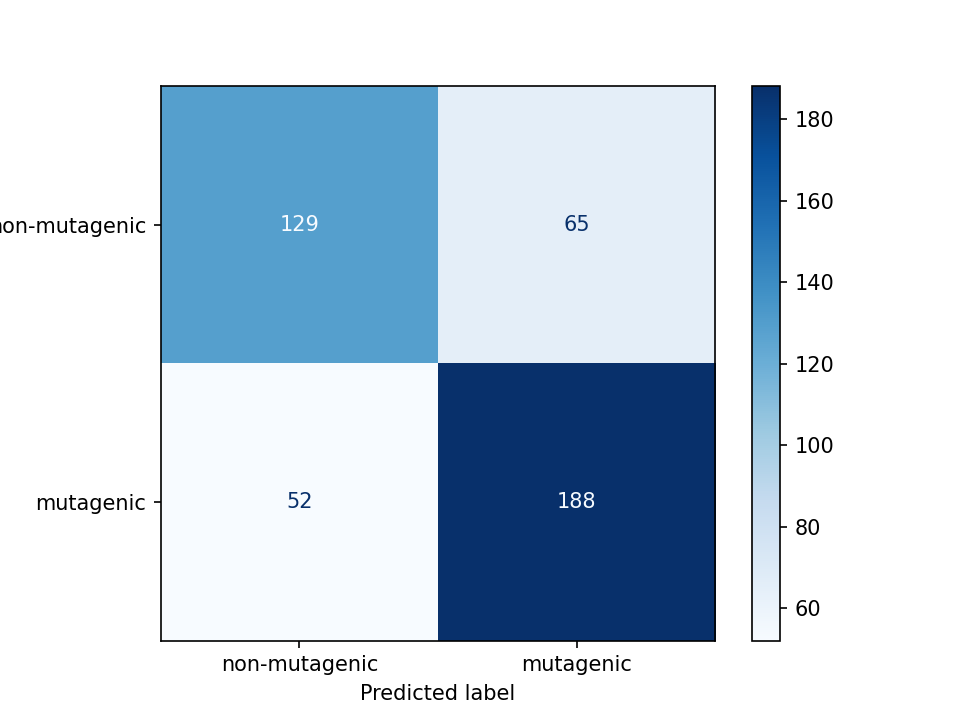

In [16]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
k = int(np.argmax([v for _, v in runs]))
model, p_best = runs[k][0], P[k]
print("seed", final_seeds[k], "  val acc =", round(runs[k][1], 4), "  test:", {m: round(float(v), 4) for m, v in scores(y_test, p_best).items()})
print("trainable parameters:", sum(p.numel() for p in model.parameters()))
ConfusionMatrixDisplay(confusion_matrix(y_test, p_best > .5), display_labels=['non-mutagenic', 'mutagenic']).plot(cmap='Blues')
plt.savefig('ginp_confusion.png', dpi=150); plt.show()

## 17. Permutation invariance, checked

A graph has no natural node order, so the prediction must not change when the atoms are stored in a different order: $\mathrm{READOUT}(\mathbf{P}\mathbf{H})=\mathrm{READOUT}(\mathbf{H})$ for every permutation matrix $\mathbf{P}$. We shuffle the nodes of every test molecule, relabel the edges, and compare the predictions. Floating-point sums in a different order give differences of about $10^{-6}$. With SAGPool one more effect can appear: the top-k cut is a hard threshold, so when two nodes' scores differ by less than that rounding error, the shuffle can swap which of them is kept and the probability moves by more than $10^{-6}$. That is a property of hard top-k selection, not a bug; a bug would flip many predictions.

In [17]:
def shuffle_nodes(g, seed):
    gen = torch.Generator().manual_seed(seed)
    perm = torch.randperm(g.num_nodes, generator=gen)
    inv = torch.empty_like(perm); inv[perm] = torch.arange(g.num_nodes)
    h = g.clone()
    h.x, h.pe, h.edge_index = g.x[perm], g.pe[perm], inv[g.edge_index]
    return h

p_shuf = predict(model, batches([shuffle_nodes(g, i) for i, g in enumerate(test_set)]))
print("largest change in P(mutagenic) after shuffling:", float(np.abs(p_shuf - p_best).max()))
print("predictions that flip:", int(((p_shuf > .5) != (p_best > .5)).sum()), "of", len(p_best))

largest change in P(mutagenic) after shuffling: 1.1920928955078125e-07
predictions that flip: 0 of 434


## 18. Ablation: which tricks matter on FRANKENSTEIN?

This mirrors the ablation tables of Luo et al. We keep the tuned hyperparameters, switch off **one** trick at a time, and retrain on `abl_seeds`: no normalization, no dropout, no residual connections, no FFN, no positional encoding, and finally all tricks off (the plain GIN with the tuned width, depth and readout). `Δ acc` is the change against the full GIN⁺ on the same seeds.

                           acc      f1     auc  acc std   Δ acc
full GIN⁺               0.7166  0.7107  0.7931   0.0217  0.0000
no normalization        0.7290  0.7235  0.7904   0.0141  0.0124
no dropout              0.7189  0.7146  0.7790   0.0078  0.0023
no residual             0.6963  0.6908  0.7672   0.0228 -0.0203
no FFN                  0.7065  0.7009  0.7772   0.0229 -0.0101
no positional encoding  0.6857  0.6750  0.7424   0.0206 -0.0309
all tricks off          0.6659  0.6512  0.7235   0.0217 -0.0507


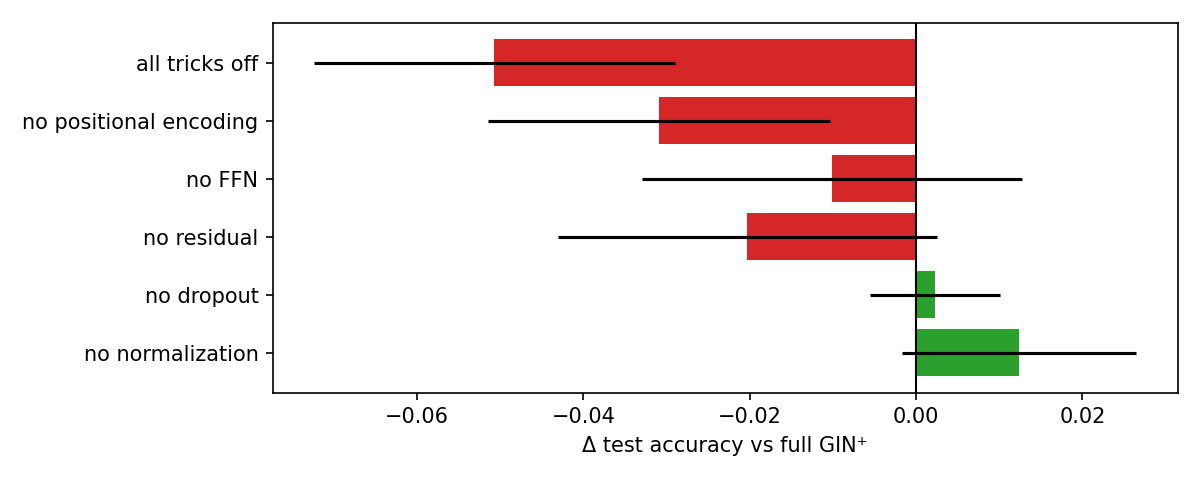

In [18]:
def run(c, seeds=abl_seeds, tr=None, va=None, te=None):
    te = te or test_b
    return pd.DataFrame([scores(y_test, predict(fit(c, s, tr, va)[0], te)) for s in seeds])

def table(d):
    t = pd.DataFrame({k: v.mean() for k, v in d.items()}).T
    t['acc std'] = [v.acc.std() for v in d.values()]
    t['Δ acc'] = t.acc - t.acc.iloc[0]
    return t.round(4)

def bars(t, ref, fname):
    d = t.iloc[1:]
    plt.figure(figsize=(8, 0.5 + 0.45 * len(d)))
    plt.barh(d.index, d['Δ acc'], xerr=d['acc std'], color=['tab:red' if v < 0 else 'tab:green' for v in d['Δ acc']])
    plt.axvline(0, color='k', lw=1); plt.xlabel(f"Δ test accuracy vs {ref}")
    plt.tight_layout(); plt.savefig(fname, dpi=150); plt.show()

abl = {'full GIN⁺': tuned.iloc[:len(abl_seeds)]}
for name, change in [('no normalization', dict(norm=False)), ('no dropout', dict(dropout=0.0)),
                     ('no residual', dict(res=False)), ('no FFN', dict(ffn=False)),
                     ('no positional encoding', dict(pe=False)),
                     ('all tricks off', dict(norm=False, res=False, ffn=False, pe=False))]:
    if name == 'no dropout' and best['dropout'] == 0:
        continue
    abl[name] = run(dict(best, **change))
abl_t = table(abl)
print(abl_t)
bars(abl_t, 'full GIN⁺', 'ginp_ablation.png')

## 19. Ablation: does the model need the edges and the features?

Now the architecture stays tuned and we damage the **input**, in train, validation and test alike (Milestone 3 brief, *Ablation studies*):

- **No edges** ($\mathbf{A}=\mathbf{I}$): each atom sees only itself, so message passing becomes a per-node MLP. If accuracy holds, the bonds are not being used.
- **Constant features**: every $\mathbf{x}_v$ becomes a vector of ones, so only the skeleton of the molecule is left.
- **Shuffled atoms**: the images are permuted among the atoms of the same molecule. The molecule keeps its atoms and its skeleton, but the model no longer knows which atom sits where.

The positional encodings are recomputed on the graphs without edges, so they cannot leak the structure back in.

In [19]:
def no_edges(g):
    h = g.clone(); h.edge_index = g.edge_index[:, :0]; h.pe = torch.zeros_like(g.pe); return h
def const_x(g):
    h = g.clone(); h.x = torch.ones_like(g.x); return h
gen = torch.Generator().manual_seed(0)
def shuffle_x(g):
    h = g.clone(); h.x = g.x[torch.randperm(g.num_nodes, generator=gen)]; return h

inp = {'tuned': tuned.iloc[:len(abl_seeds)]}
for name, f in [('no edges (A = I)', no_edges), ('constant features', const_x), ('shuffled atoms', shuffle_x)]:
    tr, va, te = [[f(g) for g in d] for d in [train_set, val_set, test_set]]
    inp[name] = run(best, tr=tr, va=batches(va), te=batches(te))
inp_t = table(inp)
print(inp_t)

                      acc      f1     auc  acc std   Δ acc
tuned              0.7166  0.7107  0.7931   0.0217  0.0000
no edges (A = I)   0.5724  0.5389  0.5693   0.0111 -0.1442
constant features  0.7235  0.7202  0.7851   0.0071  0.0069
shuffled atoms     0.6940  0.6850  0.7462   0.0154 -0.0226


## 20. Which readout suits FRANKENSTEIN?

Now only the readout changes and everything else stays tuned; `Δ acc` is measured against the tuned readout. The lecture's argument for hierarchical pooling is that one-shot sum, mean or max *forgets how nodes are organised*. For mutagenicity there is a second view: one small reactive group can be enough to make a molecule mutagenic, and a mean dilutes it over all the other atoms while max and sum do not.

           acc      f1     auc  acc std   Δ acc
degree  0.7166  0.7107  0.7931   0.0217  0.0000
mean    0.7138  0.7034  0.7795   0.0141 -0.0028
max     0.7189  0.7093  0.7886   0.0086  0.0023
add     0.7134  0.7062  0.7822   0.0048 -0.0032
sag     0.6876  0.6848  0.7466   0.0194 -0.0290
diff    0.7055  0.7018  0.7711   0.0162 -0.0111
mincut  0.7281  0.7250  0.7913   0.0121  0.0115


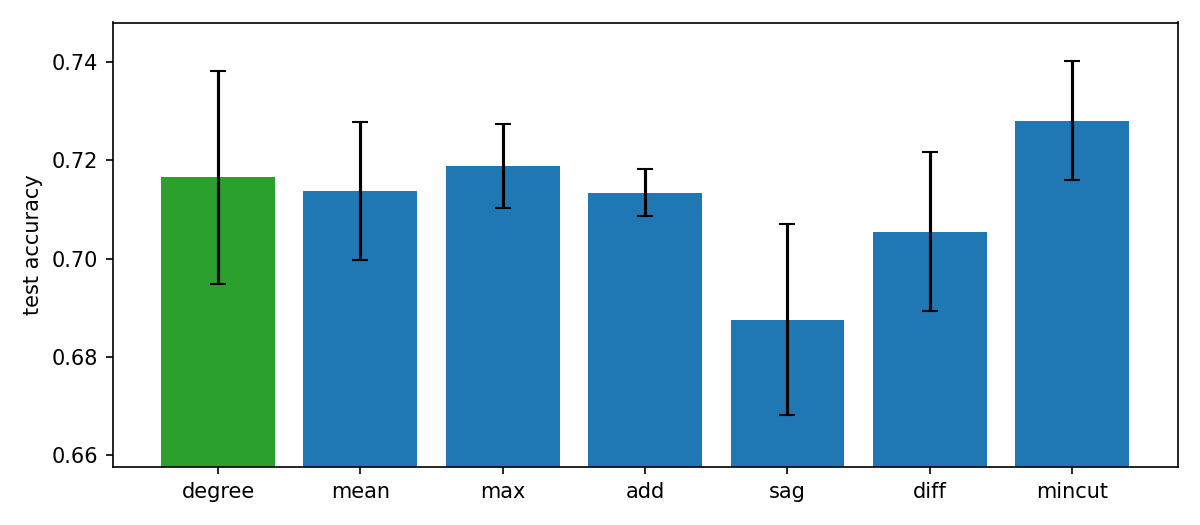

In [20]:
pool_res = {}
for p in [best['pool']] + [q for q in space['pool'] if q != best['pool']]:
    pool_res[p] = tuned.iloc[:len(abl_seeds)] if p == best['pool'] else run(dict(best, pool=p))
pool_t = table(pool_res)
print(pool_t)
plt.figure(figsize=(8, 3.5))
plt.bar(pool_t.index, pool_t.acc, yerr=pool_t['acc std'], capsize=4,
        color=['tab:green' if p == best['pool'] else 'tab:blue' for p in pool_t.index])
plt.ylim(pool_t.acc.min() - 0.03, min(1, pool_t.acc.max() + 0.02)); plt.ylabel("test accuracy")
plt.tight_layout(); plt.savefig('ginp_readout.png', dpi=150); plt.show()

## 21. Depth with and without residual connections

Lecture 17, *Finding 3*: deep stacks without residuals collapse through over-smoothing, because repeated neighbourhood aggregation pulls every node of a graph towards the same embedding. The average molecule has 17 atoms, so a few hops already cover a functional group and its surroundings. We train 2, 4, 8 and 16 layers with and without residuals on `sweep_seeds`.

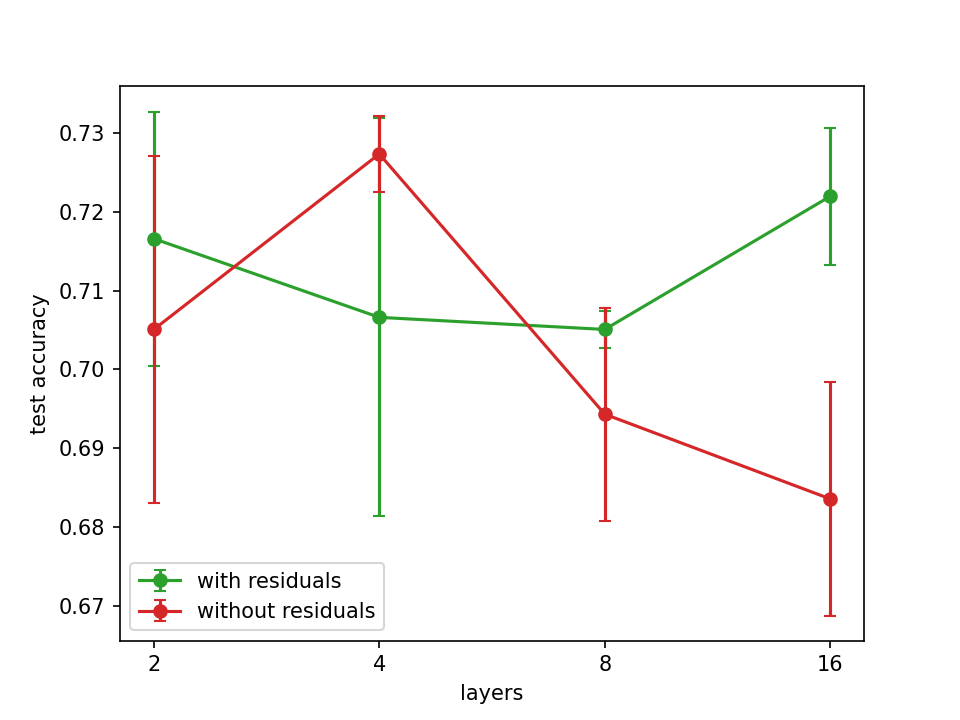

In [21]:
Ls = [2, 4, 8, 16]
depth = {(r, L): run(dict(best, res=r, layers=L), sweep_seeds) for r in [True, False] for L in Ls}
for r, col in [(True, 'tab:green'), (False, 'tab:red')]:
    plt.errorbar(Ls, [depth[r, L].acc.mean() for L in Ls], [depth[r, L].acc.std() for L in Ls],
                 marker='o', capsize=3, color=col, label='with residuals' if r else 'without residuals')
plt.xscale('log', base=2); plt.xticks(Ls, Ls); plt.xlabel("layers"); plt.ylabel("test accuracy"); plt.legend()
plt.savefig('ginp_depth.png', dpi=150); plt.show()

## 22. Dropout sensitivity

Lecture 17, *Finding 4*: dropout inside message passing distorts every aggregated message, and on the benchmarks of Luo et al. the best rates were mostly 0.2 or lower. We sweep the rate on `sweep_seeds` with everything else tuned.

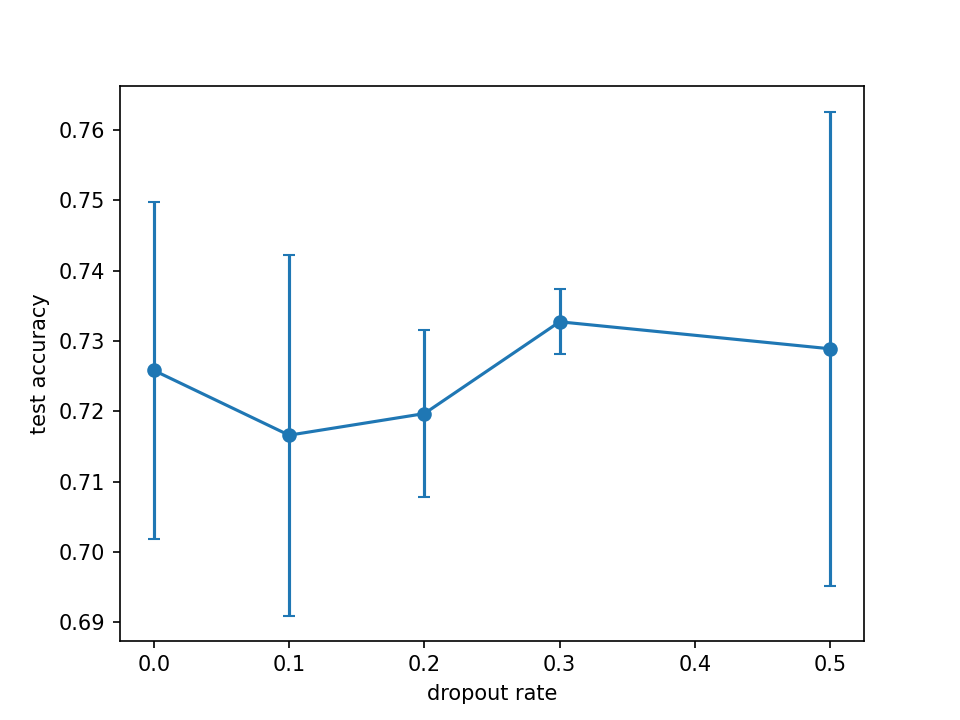

In [22]:
rates = [0.0, 0.1, 0.2, 0.3, 0.5]
drop = {p: run(dict(best, dropout=p), sweep_seeds) for p in rates}
plt.errorbar(rates, [drop[p].acc.mean() for p in rates], [drop[p].acc.std() for p in rates], marker='o', capsize=3)
plt.xlabel("dropout rate"); plt.ylabel("test accuracy")
plt.savefig('ginp_dropout.png', dpi=150); plt.show()

## 23. Visualisation: t-SNE of graph embeddings

`embed` returns the vector the classifier sees, one per molecule. t-SNE maps these vectors to 2D while keeping near neighbours near. On the left is the mean of each molecule's raw node features, on the right the tuned GIN⁺ embedding. Colour is the true class, and crosses are molecules the model gets wrong: if they sit on the border between the two clouds, the model fails on genuinely ambiguous cases. The silhouette score, computed in the original space, measures class separation from $-1$ to $1$.

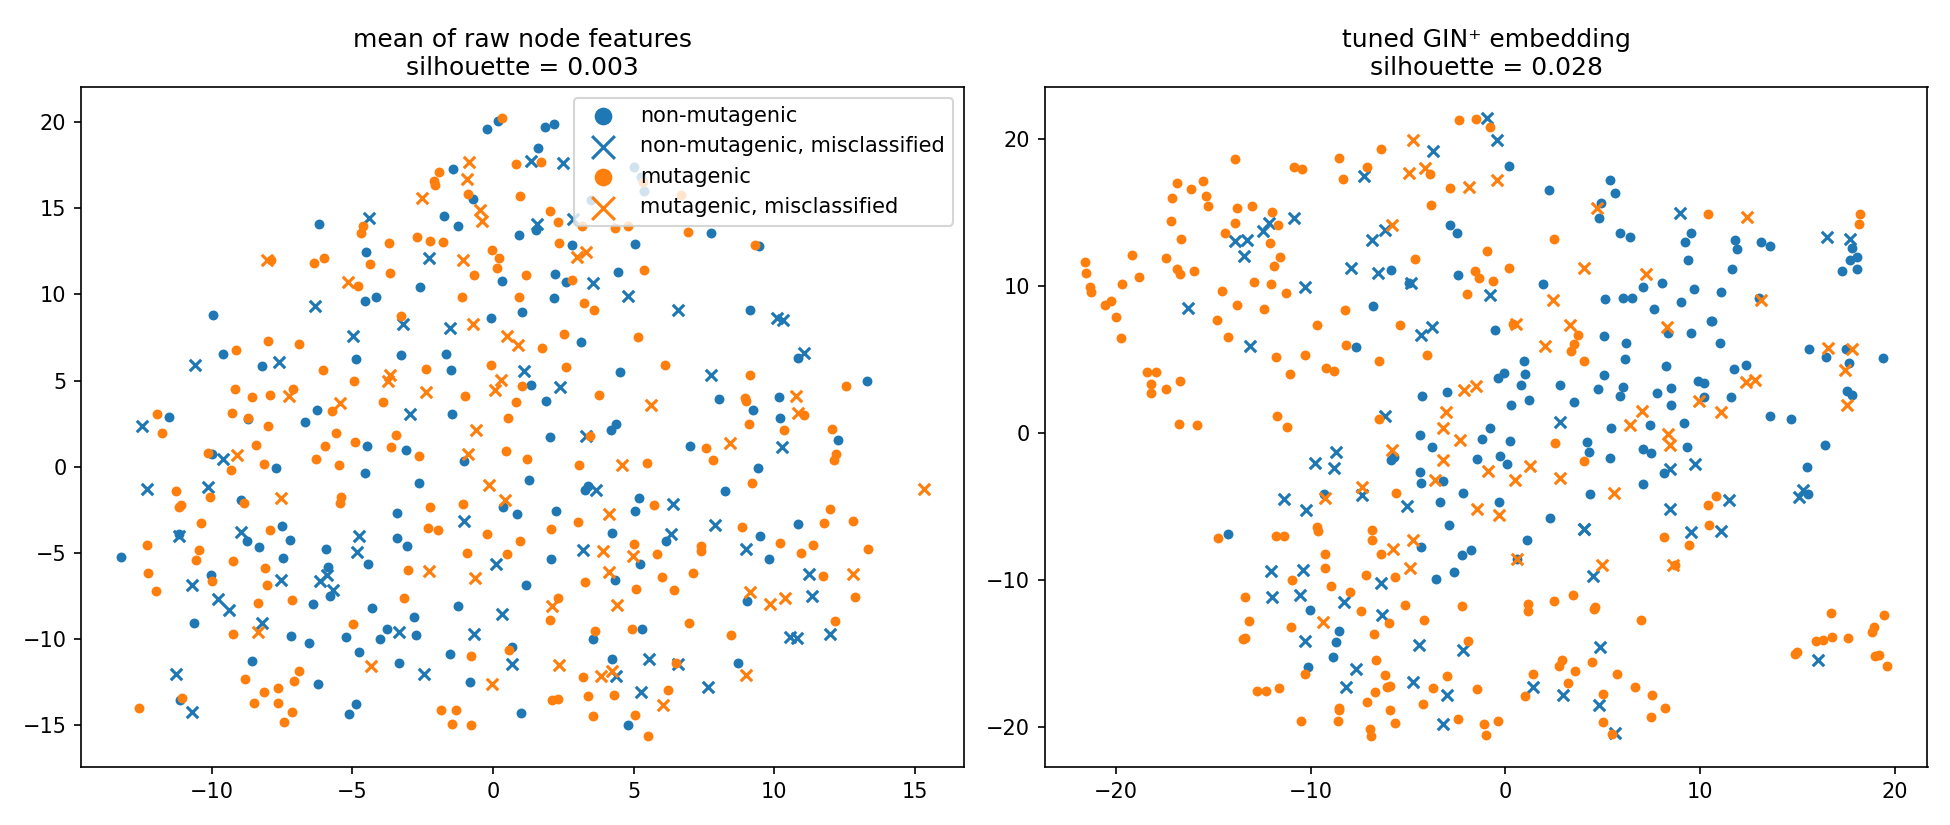

In [23]:
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score

@torch.no_grad()
def embed_all(model, bs):
    model.eval()
    return torch.cat([model.embed(b.x, b.edge_index, b.pe, b.batch) for b in bs]).cpu().numpy()

Z = {'mean of raw node features': torch.cat([global_mean_pool(b.x, b.batch) for b in test_b]).cpu().numpy(),
     'tuned GIN⁺ embedding': embed_all(model, test_b)}
sil = {name: silhouette_score(E, y_test) for name, E in Z.items()}
wrong = (p_best > .5) != y_test
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
for a, (name, E) in zip(ax, Z.items()):
    T2 = TSNE(2, init='pca', random_state=0, perplexity=min(30, len(E) // 4)).fit_transform(E)
    for c, col, lab in [(0, 'tab:blue', 'non-mutagenic'), (1, 'tab:orange', 'mutagenic')]:
        a.scatter(*T2[(y_test == c) & ~wrong].T, s=14, c=col, label=lab)
        a.scatter(*T2[(y_test == c) & wrong].T, s=30, c=col, marker='x', label=f'{lab}, misclassified')
    a.set_title(f"{name}\nsilhouette = {sil[name]:.3f}")
ax[0].legend(markerscale=2)
plt.tight_layout(); plt.savefig('ginp_tsne.png', dpi=150); plt.show()

## 24. Efficiency: what does each readout cost?

Milestone 3 asks for the computational cost of accuracy. For the tuned model and for each readout we measure the number of trainable parameters, the training time per epoch, the time to predict all 434 test molecules, and the peak GPU memory during one epoch. Dense DiffPool and MinCutPool build an $n_{\max}\times n_{\max}$ adjacency for every graph in the batch, so they should be the most expensive. Each number is the median of three epochs after one warm-up epoch.

In [24]:
def cost(c):
    seed_everything(0)
    m = Net(**c).to(device)
    opt = torch.optim.Adam(m.parameters(), lr=c['lr'])
    loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
    times = []
    if device == 'cuda':
        torch.cuda.reset_peak_memory_stats()
    for e in range(4):
        if device == 'cuda': torch.cuda.synchronize()
        t = time.time(); m.train()
        for b in loader:
            b = b.to(device); opt.zero_grad()
            (F.cross_entropy(m(b.x, b.edge_index, b.pe, b.batch), b.y) + m.aux).backward(); opt.step()
        if device == 'cuda': torch.cuda.synchronize()
        times.append(time.time() - t)
    t = time.time(); predict(m, test_b)
    if device == 'cuda': torch.cuda.synchronize()
    return dict(params=sum(p.numel() for p in m.parameters()), s_per_epoch=float(np.median(times[1:])),
                infer_s=time.time() - t, peak_mb=torch.cuda.max_memory_allocated() / 2**20 if device == 'cuda' else float('nan'))

eff = pd.DataFrame({p: cost(dict(best, pool=p)) for p in space['pool']}).T
eff['test acc'] = pool_t.acc.reindex(eff.index)
print(eff.round(4))

          params  s_per_epoch  infer_s   peak_mb  test acc
mean    403685.0       0.7222   0.0074  136.2563    0.7138
max     403685.0       0.7388   0.0070  137.0913    0.7189
add     403685.0       0.7125   0.0070  136.2563    0.7134
degree  436453.0       0.8400   0.0098  136.0410    0.7166
sag     420198.0       0.8832   0.0113  136.0034    0.6876
diff    420842.0       1.0159   0.0144  221.0166    0.7055
mincut  437226.0       1.0562   0.0152  222.1279    0.7281


## 25. Robustness: missing edges and noisy features

Without retraining, we damage only the **test** molecules and measure how fast accuracy falls (Milestone 3 brief, *Robustness*):

- **Edge removal**: drop a fraction of the bonds, both directions together, at random; positional encodings are recomputed on the damaged graph.
- **Feature noise**: add Gaussian noise $\mathcal{N}(0,\sigma^2)$ to every pixel. The pixels lie in $[0,1]$, so $\sigma=0.5$ is a very noisy image.

Each point is the mean over three random damages.

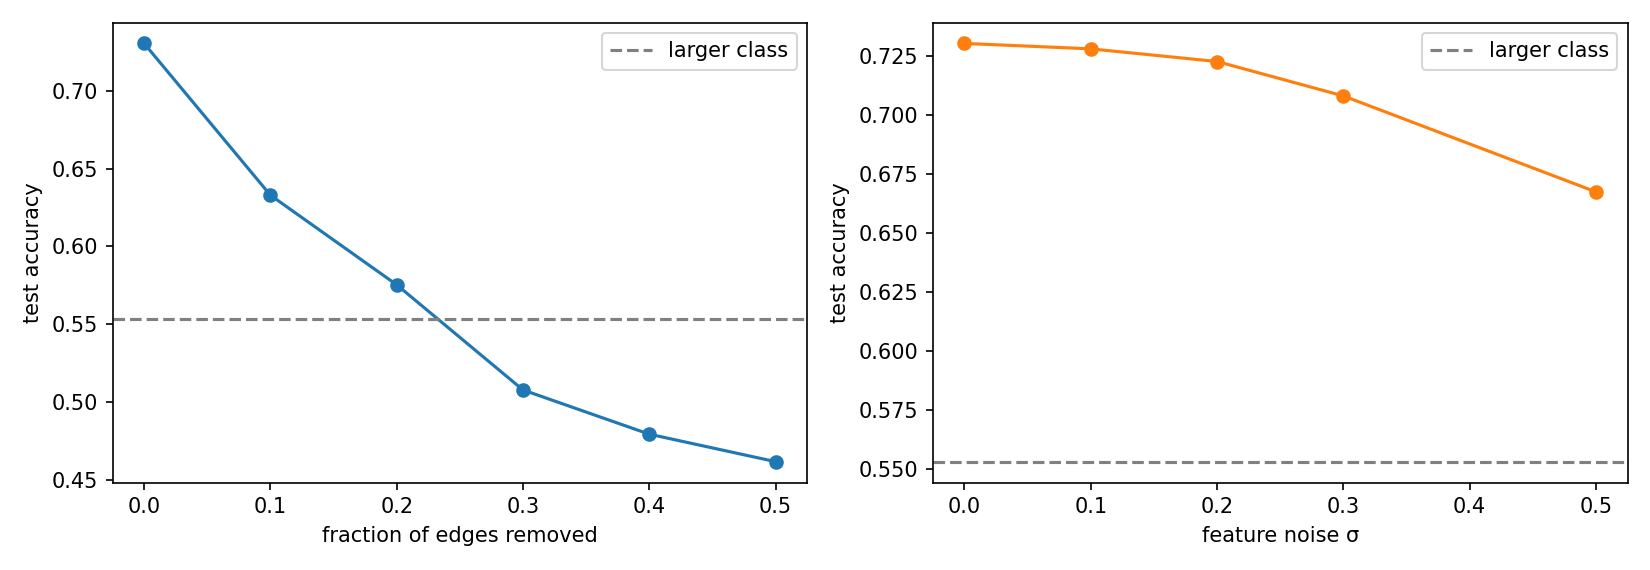

In [25]:
from torch_geometric.utils import dropout_edge

def drop_edges(g, p, seed):
    torch.manual_seed(seed)
    h = g.clone(); h.edge_index, _ = dropout_edge(g.edge_index, p=p, force_undirected=True)
    h.pe = rw(h).pe; return h
def noisy(g, s, seed):
    torch.manual_seed(seed)
    h = g.clone(); h.x = g.x + s * torch.randn_like(g.x); return h

edge_ps, sigmas = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5], [0.0, 0.1, 0.2, 0.3, 0.5]
rob_edge = {p: np.mean([accuracy_score(y_test, predict(model, batches([drop_edges(g, p, r) for g in test_set])) > .5) for r in range(3)]) for p in edge_ps}
rob_noise = {s: np.mean([accuracy_score(y_test, predict(model, batches([noisy(g, s, r) for g in test_set])) > .5) for r in range(3)]) for s in sigmas}
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(edge_ps, list(rob_edge.values()), marker='o'); ax[0].set_xlabel("fraction of edges removed")
ax[1].plot(sigmas, list(rob_noise.values()), marker='o', color='tab:orange'); ax[1].set_xlabel("feature noise σ")
for a in ax:
    a.axhline(majority, ls='--', c='grey', label='larger class'); a.set_ylabel("test accuracy"); a.legend()
plt.tight_layout(); plt.savefig('ginp_robustness.png', dpi=150); plt.show()

## 26. Error analysis by graph shape

The brief's examples are node-level (accuracy by node degree); for graph classification the natural unit is the molecule. We describe every test molecule by three structural properties and group the test accuracy by tertile of each:

- **size** $|V|$, the number of atoms;
- **average degree**, the number of bonds per atom, which is larger in molecules with rings and branches;
- **rings**, the number of independent rings.

PROTEINS used the clustering coefficient as its third property. Molecules have almost no triangles, so here it would be zero for 94% of them, and we count rings instead.


size
                  acc    n  mutagenic
size                                
(2.999, 12.0]  0.678  149      0.497
(12.0, 19.0]   0.778  144      0.625
(19.0, 194.0]  0.738  141      0.539

degree
                   acc    n  mutagenic
degree                               
(1.332, 2.0]    0.718  216      0.454
(2.0, 2.164]    0.740   73      0.479
(2.164, 2.476]  0.745  145      0.738

rings
                  acc    n  mutagenic
rings                               
(-0.001, 1.0]  0.717  205      0.449
(1.0, 3.0]     0.724  145      0.600
(3.0, 12.0]    0.774   84      0.726


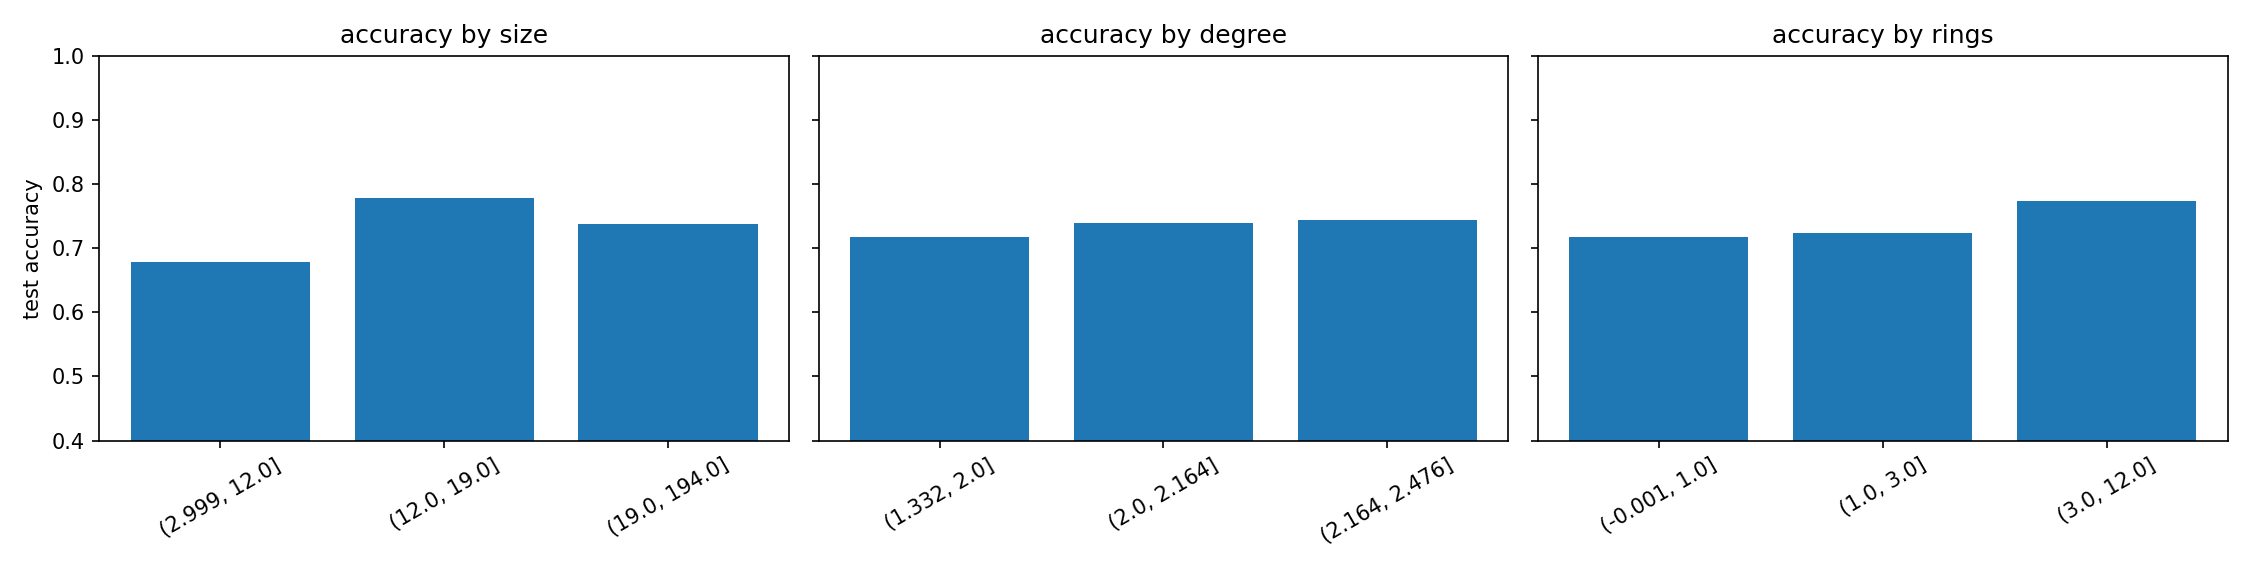

In [26]:
def shape(g):
    return dict(size=g.num_nodes, degree=g.num_edges / g.num_nodes, rings=n_rings(g))

shp = pd.DataFrame([shape(g) for g in test_set])
shp['correct'] = (p_best > .5) == y_test
shp['mutagenic'] = y_test
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
topo = {}
for a, col in zip(ax, ['size', 'degree', 'rings']):
    q = pd.qcut(shp[col], 3, duplicates='drop')
    t = shp.groupby(q, observed=True).agg(acc=('correct', 'mean'), n=('correct', 'size'), mutagenic=('mutagenic', 'mean'))
    topo[col] = t.reset_index().astype(str).to_dict('records')
    print(f"\n{col}\n", t.round(3))
    a.bar([str(i) for i in t.index], t.acc, color='tab:blue'); a.set_title(f"accuracy by {col}")
    a.tick_params(axis='x', rotation=30); a.set_ylim(0.4, 1)
ax[0].set_ylabel("test accuracy")
plt.tight_layout(); plt.savefig('ginp_topology.png', dpi=150); plt.show()

## 27. Explainability: which atoms drive the prediction?

We ask **GNNExplainer** (Ying et al., NeurIPS 2019) which atoms of a molecule the tuned model relies on. For one graph it learns a soft mask over the nodes that keeps the prediction while using as few nodes as possible, and returns an importance score per node.

A mask is only useful if it is faithful. We measure **fidelity** by deletion: remove the top 10% most important atoms and record how much the predicted probability of the predicted class drops. If the explainer is right, this drop should be much larger than when we remove the same number of *random* atoms. We do this on up to 100 test molecules with at least 20 nodes. We also count which skeleton positions the explainer ranks highest (chain ends, chain or ring atoms, branching atoms), against how common each position is.

GNNExplainer writes its mask into the message-passing layers of the model it explains, which corrupts that model for later use, so we explain a copy.

In [27]:
from torch_geometric.explain import Explainer, GNNExplainer
from torch_geometric.utils import subgraph

expl = Explainer(model=copy.deepcopy(model), algorithm=GNNExplainer(epochs=100),
                 explanation_type='model', node_mask_type='object', edge_mask_type=None,
                 model_config=dict(mode='multiclass_classification', task_level='graph', return_type='raw'))

@torch.no_grad()
def prob(g):
    model.eval(); g = g.clone().to(device)  # Data.to() moves in place; keep the caller's graph on the CPU
    return model(g.x, g.edge_index, g.pe, g.edge_index.new_zeros(g.num_nodes)).softmax(1)[0].cpu()

def delete(g, drop):
    keep = torch.ones(g.num_nodes, dtype=torch.bool); keep[drop] = False
    ei, _ = subgraph(keep, g.edge_index, relabel_nodes=True, num_nodes=g.num_nodes)
    h = g.clone(); h.x, h.edge_index = g.x[keep], ei; h.pe = rw(h).pe; return h

rng = np.random.default_rng(0)
cand = [i for i, g in enumerate(test_set) if g.num_nodes >= 20]
picked = rng.choice(cand, size=min(100, len(cand)), replace=False)
fid, masks, top_types = [], {}, []
for i in picked:
    g = test_set[i].clone().to(device)
    m_ = expl(g.x, g.edge_index, pe=g.pe, batch=g.edge_index.new_zeros(g.num_nodes)).node_mask.flatten().cpu()
    masks[int(i)] = m_
    g = g.cpu(); p0 = prob(g); c = int(p0.argmax()); kk = max(1, int(0.1 * g.num_nodes))
    order = torch.argsort(m_, descending=True)
    rand = torch.from_numpy(rng.permutation(g.num_nodes))
    top_types += role(g.edge_index, g.num_nodes)[order[:kk]].tolist()
    fid.append(dict(top=float(p0[c] - prob(delete(g, order[:kk]))[c]), random=float(p0[c] - prob(delete(g, rand[:kk]))[c])))
fid = pd.DataFrame(fid)
print("mean drop in confidence, top-10% atoms removed:   ", round(fid.top.mean(), 4))
print("mean drop in confidence, random 10% atoms removed:", round(fid.random.mean(), 4))
names = ['chain end', 'chain / ring', 'branch']
share_all = np.bincount(torch.cat([role(test_set[i].edge_index, test_set[i].num_nodes) for i in picked]), minlength=3)
share_all = share_all / share_all.sum()
share_top = np.bincount(top_types, minlength=3) / len(top_types)
type_share = pd.DataFrame({'all nodes': share_all, 'top-10% nodes': share_top}, index=names)
print(type_share.round(3))

mean drop in confidence, top-10% atoms removed:    0.1547
mean drop in confidence, random 10% atoms removed: 0.1195
              all nodes  top-10% nodes
chain end         0.201          0.207
chain / ring      0.454          0.452
branch            0.345          0.341


## 28. Explained molecules

We draw three explained molecules, one correctly classified mutagen, one correctly classified non-mutagen, and one error. Node colour shows GNNExplainer's importance and node shape the position in the skeleton (circle chain end, square chain or ring atom, triangle branching atom). A useful explanation would point at a compact group of atoms, such as a functional group, rather than spread its importance evenly. Below each molecule are the images of its three most important atoms.

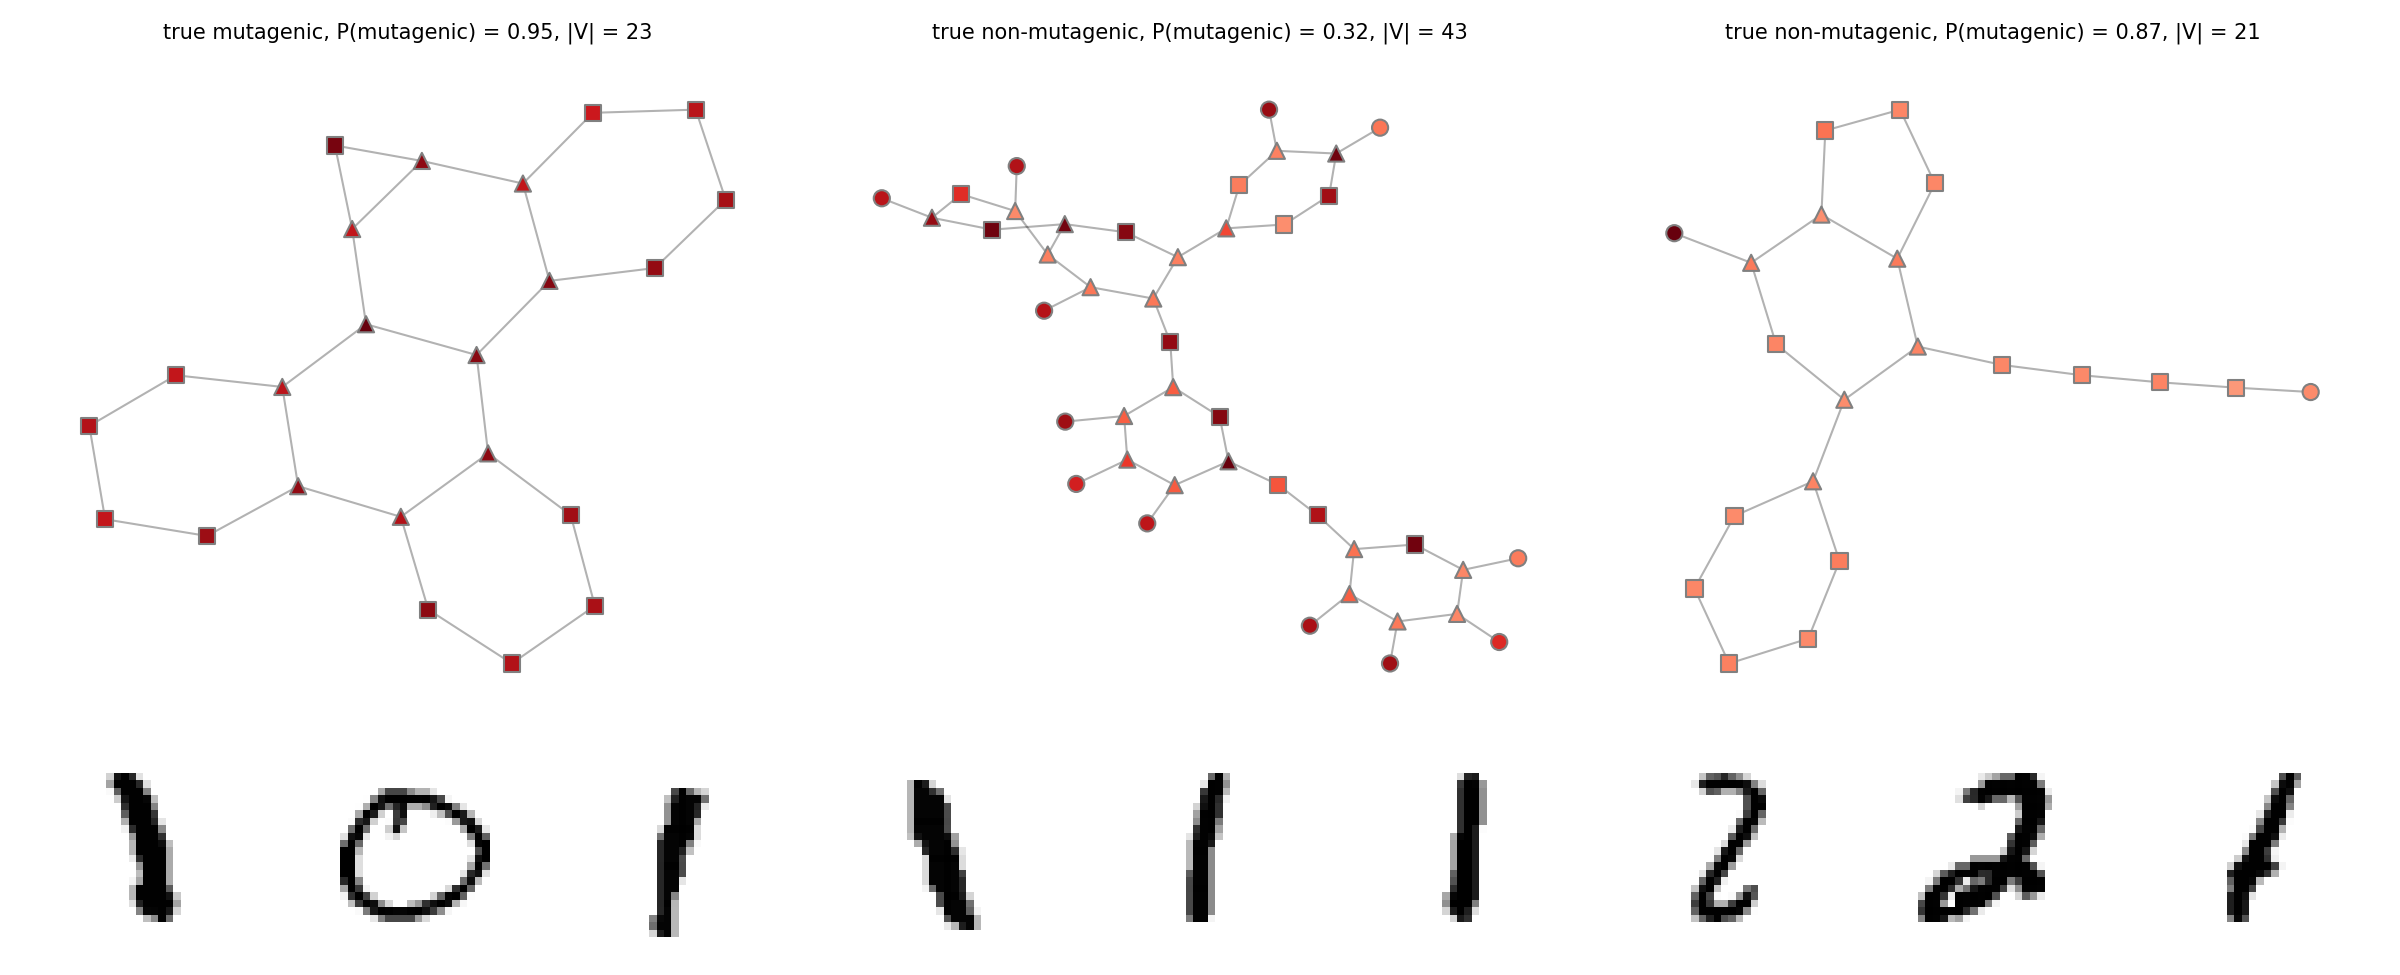

In [28]:
def pick(cond):
    for i in masks:
        if cond(i): return i
chosen = [pick(lambda i: y_test[i] == 1 and p_best[i] > .5), pick(lambda i: y_test[i] == 0 and p_best[i] <= .5),
          pick(lambda i: (p_best[i] > .5) != y_test[i])]
fig = plt.figure(figsize=(16, 6.5))
for col, i in enumerate(chosen):
    if i is None: continue
    a = plt.subplot2grid((4, 9), (0, 3 * col), rowspan=3, colspan=3)
    g = test_set[i]; G = to_networkx(g, to_undirected=True); pos = nx.kamada_kawai_layout(G); w = masks[i].numpy()
    kind = role(g.edge_index, g.num_nodes).numpy()
    nx.draw_networkx_edges(G, pos, ax=a, alpha=.3)
    for t, shp_ in zip(range(3), 'os^'):
        nl = [v for v in range(len(w)) if kind[v] == t]
        nx.draw_networkx_nodes(G, pos, nodelist=nl, node_color=w[nl], cmap='Reds', vmin=0, vmax=w.max(), node_shape=shp_, node_size=60, edgecolors='grey', ax=a)
    a.set_title(f"true {'mutagenic' if y_test[i] else 'non-mutagenic'}, P(mutagenic) = {p_best[i]:.2f}, |V| = {len(w)}", fontsize=10); a.axis('off')
    for j, v in enumerate(w.argsort()[::-1][:3]):
        b = plt.subplot2grid((4, 9), (3, 3 * col + j)); b.imshow(image(g.x[int(v)]), cmap='gray_r'); b.axis('off')
plt.tight_layout(); plt.savefig('ginp_explained_molecules.png', dpi=150); plt.show()

## 29. Explainability: which input matters, and which pixels?

Each atom has two inputs: its image (780 pixels) and its positional encoding (16 numbers). We measure the drop in confidence when one of them is replaced by its training-set mean in every atom (the brief's *drop in confidence when features are masked*).

Then we mask the image piece by piece: each $4\times4$ patch is replaced by its mean in every atom, and the drop in confidence is drawn at the position of the patch. A model that really looks at the digits should react to the centre of the image, where the strokes are, and not to the empty border.

                          conf_drop     acc
image (780)                  0.1622  0.6129
positional encoding (16)     0.1595  0.5553


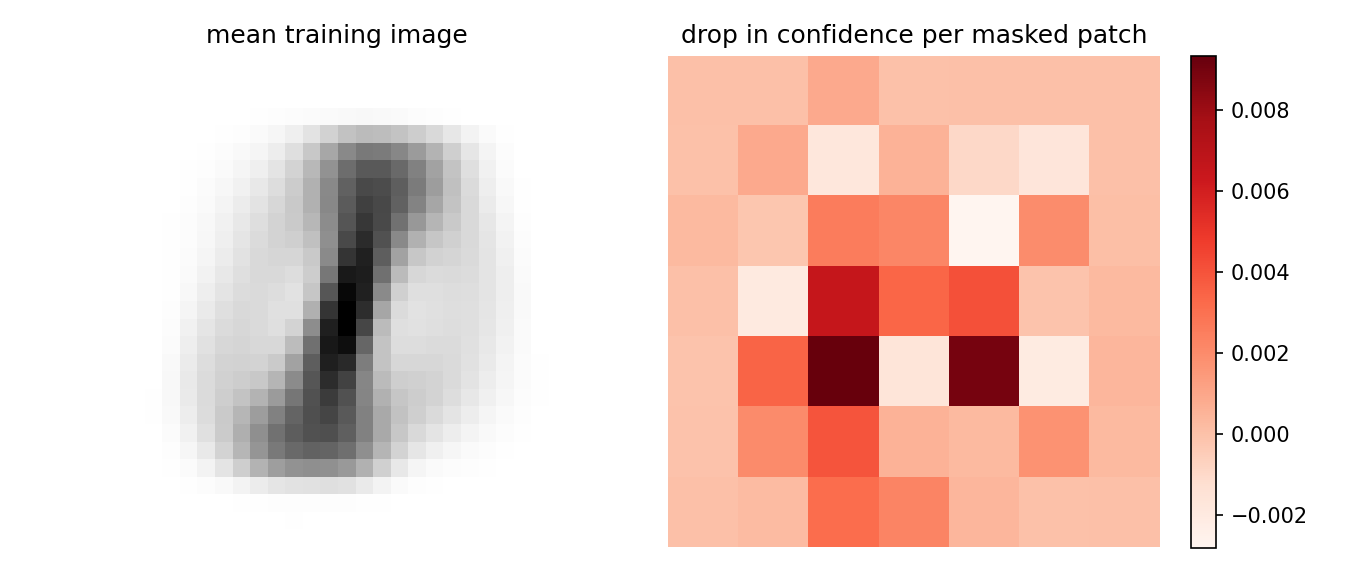

In [29]:
mu_x, mu_pe = torch.cat([g.x for g in train_set]).mean(0), torch.cat([g.pe for g in train_set]).mean(0)
def mask_x(g, cols):
    h = g.clone(); h.x = g.x.clone(); h.x[:, cols] = mu_x[cols]; return h
def mask_pe(g):
    h = g.clone(); h.pe = mu_pe.expand_as(g.pe).clone(); return h

p_c = np.where(p_best > .5, p_best, 1 - p_best)
def effect(gs):
    p = predict(model, batches(gs))
    return dict(conf_drop=float(np.mean(p_c - np.where(p_best > .5, p, 1 - p))), acc=accuracy_score(y_test, p > .5))

feat = pd.DataFrame({'image (780)': effect([mask_x(g, slice(0, 780)) for g in test_set]),
                     'positional encoding (16)': effect([mask_pe(g) for g in test_set])}).T
print(feat.round(4))
grid = torch.arange(784).view(28, 28)
patch = np.zeros((7, 7))
for r in range(7):
    for c in range(7):
        cols = grid[4 * r:4 * r + 4, 4 * c:4 * c + 4].flatten()
        patch[r, c] = effect([mask_x(g, cols[cols < 780]) for g in test_set])['conf_drop']
fig, ax = plt.subplots(1, 2, figsize=(9, 3.8))
ax[0].imshow(image(mu_x), cmap='gray_r'); ax[0].set_title("mean training image")
im = ax[1].imshow(patch, cmap='Reds'); ax[1].set_title("drop in confidence per masked patch"); plt.colorbar(im)
for a in ax: a.axis('off')
plt.tight_layout(); plt.savefig('ginp_patches.png', dpi=150); plt.show()

## 30. Save the results

Everything needed to compare this model with the others goes into one JSON file. The per-run test probabilities are saved too, so the errors of all models can later be compared graph by graph.

In [30]:
import json
res = dict(model='GIN⁺', dataset='FRANKENSTEIN', references=dict(majority=majority, size_only=size_acc, bag_of_nodes=bag_acc),
           split=dict(rule='stratified 80/10/10, random_state=0', train=train_idx.tolist(), val=val_idx.tolist(), test=test_idx.tolist()),
           best_config=best, plain=base.agg(['mean', 'std']).to_dict(), tuned=tuned.agg(['mean', 'std']).to_dict(),
           tuned_runs=tuned.to_dict('list'), params=sum(p.numel() for p in model.parameters()),
           permutation_max_change=float(np.abs(p_shuf - p_best).max()),
           ablation=abl_t.to_dict('index'), input_ablation=inp_t.to_dict('index'), readout=pool_t.to_dict('index'),
           depth={f'res={r}, layers={L}': [v.acc.mean(), v.acc.std()] for (r, L), v in depth.items()},
           dropout={str(p): [v.acc.mean(), v.acc.std()] for p, v in drop.items()},
           silhouette=sil, efficiency=eff.to_dict('index'),
           robustness=dict(edges={str(k): v for k, v in rob_edge.items()}, noise={str(k): v for k, v in rob_noise.items()}),
           topology=topo, fidelity=fid.mean().to_dict(), explainer_types=type_share.to_dict(), feature_masking=feat.to_dict('index'), patch_masking=patch.tolist(),
           minutes=(time.time() - t0) / 60)
json.dump(res, open('ginp_frankenstein_results.json', 'w'), indent=1, default=float)
np.save('ginp_frankenstein_test_probs.npy', P)
search.to_csv('ginp_frankenstein_search.csv', index=False)
print("saved:", ', '.join(sorted(res)))
print(f"total run time: {res['minutes']:.0f} minutes")

saved: ablation, best_config, dataset, depth, dropout, efficiency, explainer_types, feature_masking, fidelity, input_ablation, minutes, model, params, patch_masking, permutation_max_change, plain, readout, references, robustness, silhouette, split, topology, tuned, tuned_runs
total run time: 171 minutes


## 31. Conclusion

The tuned GIN⁺ reaches a test accuracy of $0.720\pm0.020$ over ten seeds (macro-F1 0.713, ROC-AUC 0.792). The larger class gives 0.553, size alone 0.576 and the plain GIN 0.653. The plain GIN already reaches 0.653, unlike the plain GCN and plain GPS, which stay at the majority rate.

- Positional encoding (−3.1 points without it) and residuals (−2.0) help most. The FFN is worth about 1 point, and normalization and dropout do not help on the test split; all single-trick changes except the positional encoding are near or below the seed spread of about 2 points.
- The bonds are essential (0.572 without them). Constant features score 0.724 against 0.717 for the full input, so this GIN⁺ gains nothing measurable from the images.
- Six of the seven readouts lie within 0.706 to 0.728 and cannot be separated reliably: MinCutPool 0.728, max 0.719, degree-aware 0.717. Only SAGPool (0.688) falls behind.
- Residuals matter once the network is deep: at 16 layers 0.722 with them and 0.684 without.
- Random bond removal is very damaging (below the majority rate at 30%), while pixel noise up to σ = 0.2 costs under 1 point.
- GNNExplainer is only weakly faithful: 0.155 drop for its top atoms against 0.120 for random ones. It shows no preference for chain ends, rings or branches.